# Preprocessing and region curation for sequence to accessibility modelling



In [1]:
import os
import sys
from pathlib import Path

def find_repo_root(marker="environment.yml"):
    """Walk up from the current working directory until a folder containing `marker` is found."""
    start = Path().resolve()
    for parent in [start, *start.parents]:
        if (parent / marker).exists():
            return parent
    raise RuntimeError(
        f"Could not find repo root: no '{marker}' found in {start} or any parent directory."
    )

repo_base_dir = str(find_repo_root())
os.environ["REPO_BASE_DIR"] = repo_base_dir  # so %%bash cells below can use $REPO_BASE_DIR

import pandas as pd

### Data for sequence-to-function modelling

When training sequence-to-function models, we always need DNA sequences that can serve as input to our model as well as a target quantity that we want to predict.<br>
When setting out to model accessibility in a new cell type, one first needs to process data to be in a suitable formats and curate sets of "positive" and "negative" (control) regions for training 

In the following, we will 
- Perform some sanity checks on the ATAC data
- Call ATAC peaks (accessibile regions in the genome)
- Curate a set of peak and non-peak (=control) regions for model training
- Create data loaders that can yield batches of of example regions for model training

We will be using bulk ATAC-seq data of a human lymphoblastoid cell line (GM12878 cells) from the ENCODE dataset collection.<br>


### The ATAC signal

For all downstream tasks, we will start from mapped ATAC reads, that means <b>ATAC reads aligned to a reference genome</b>.

These aligned reads can be present in BAM or BEDPE format. Whereas bulk ATAC pipelines usually yield aligned reads in BAM format, single cell ATAC data processed with 10x genomic's cellranger pipeline is given in BEDPE format (fragments.tsv files), meaning that we have a file with tab seperated values where each row corresponds to an ATAC fragment (=pair of reads from paired end sequencing) described with (0-based) genomic coordinates (chromosome,start,end) together with a cell barcode that indicates which cell the fragment came from. 

The mural trophectoderm data that we are using as an example is part of a 10x single cell multiome (scRNA+scATAC) dataset, the mTE_fragments.tsv.gz file used in the following is a so called "pseudobulk", meaning it represents the aggregate ATAC signal for all mural trophectoderm cells in the dataset (i.e. all ATAC fragments from all mural trophectoderm cells)

Starting from a file of mapped and filtered reads/fragments is the "common entry point" for sequence to accessibility modelling regardless of whether the original data is single cell or bulk. 
How the mapped reads and pseudobulk files are obtained is shown in following tutorials (TO DO):
- (bulk ATAC tutorial)
- (single cell ATAC tutorial)

### The ATAC signal

For all downstream tasks, we will start from mapped ATAC reads, that means <b>ATAC reads aligned to a reference genome</b>.<br>
These aligned reads are present in BAM format that holds rich information about every mapped ATAC read.<br>
For most of our needs it is however enough to know where reads start and end, which is why for visualisations as well as for model training later on we well convert the data to the more lightweight bigwig format.
(BAM files can be viewed and manipulated with samtools)

In [2]:
%%bash

BAM=$REPO_BASE_DIR/example_data/ENCODE_cellines/GM12878/ENCFF415FEC.bam

samtools view $BAM | head

J00118:569:HGKLCBBXY:6:2212:20720:38170	99	chr1	9986	2	101M	=	9989	104	CCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTCACCCTAACCCGAACCCTC	AAFFFJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJJFJJJJFFJFAJF-FJFJJAF<-A<-<-7---<F-F--AJA-7<7-A-----7---	MC:Z:101M	MD:Z:0N0N0N0N0N0N0N0N0N0N0N0N0N0N0N67A10T6A0	PG:Z:MarkDuplicates	XG:i:0	NM:i:18	XM:i:18	XN:i:15	XO:i:0	MQ:i:2	AS:i:-24	XS:i:-9	YS:i:-59	YT:Z:CP
J00118:569:HGKLCBBXY:6:2228:25672:45027	99	chr1	9986	255	101M	=	9990	105	CCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAAACCGAAACCAAACCCTAACCGTAACCCTAAGGCTAACCCAA	A<AAAJAAFFFJFJJAAFF<JFJJJ7A--FF7F<F<-FA<A7-FJ<FF-JJ-J7--<-<J7FJ7A7--A-A--<A7------A----7-7----------7	MC:Z:101M	MD:Z:0N0N0N0N0N0N0N0N0N0N0N0N0N0N0N45C2T2C2T10C9C0C7T1	PG:Z:MarkDuplicates	XG:i:0	NM:i:23	XM:i:23	XN:i:15	XO:i:0	MQ:i:255	AS:i:-41	XS:i:-35	YS:i:-61	YT:Z:CP
J00118:569:HGKLCBBXY:6:2212:20720:38170	147	chr1	9989	2	101M	=	9986	-104	ACACTACGGCCTCCACCGACACCTTCACCCCACCCTTCGCCCTCACCCTAACCC

#### Visualising ATAC coverage profiles

As a first sanity check, it is good to inspect how the ATAC profile looks like when visualised in a genome browser.
For ATAC data, we expect a fairly clear distinction into peak regions seperated by stretches without much ATAC signal. 

For visualisation, we will first convert the BAM file into a coverage bigwig file that we can easily display.<br>
We will use a script that utilized bedtools and UCSC genome browser tools under the hood.

In the IGV browser screenshot below, we can see pronounced peak regions, strong transcription start site (TSS) proximal peaks as well as TSS distal peaks,<br>
seperated by stretches without much ATAC signal. This looks so far so good and we can proceed with our analyses.

In [4]:
%%bash

mkdir -p $REPO_BASE_DIR/res/ENCODE_cellines/GM12878/ATAC_signal_files

BAM=$REPO_BASE_DIR/example_data/ENCODE_cellines/GM12878/ENCFF415FEC.bam
COVERAGE_BW=$REPO_BASE_DIR/res/ENCODE_cellines/GM12878/ATAC_signal_files/ENCFF415FEC_coverage.bw

bamCoverage -b $BAM -o $COVERAGE_BW

bamFilesList: ['/groups/stark/nikolaus.mandlburger/agent_write_dir/custom_tutorials/deepstarr_accessibility_modelling_v03/example_data/ENCODE_cellines/GM12878/ENCFF415FEC.bam']
binLength: 50
numberOfSamples: None
blackListFileName: None
skipZeroOverZero: False
bed_and_bin: False
genomeChunkSize: None
defaultFragmentLength: read length
numberOfProcessors: 1
verbose: False
region: None
bedFile: None
minMappingQuality: None
ignoreDuplicates: False
chrsToSkip: []
stepSize: 50
center_read: False
samFlag_include: None
samFlag_exclude: None
minFragmentLength: 0
maxFragmentLength: 0
zerosToNans: False
smoothLength: None
save_data: False
out_file_for_raw_data: None
maxPairedFragmentLength: 1000


Coverage track visualised in IGV genome browser (screenshot):

<img src="./img/GM12878_coverage_bw_screenshot.png" style="max-width: 1800px; width:100%; height: auto;">

#### ATAC signals for model training

Although the usual way of visualising ATAC tracks is to plot read or fragment coverage, 
the "true" signal in an ATAC dataset is contained in the fragment end point positions rather than the fragment coverage.<br>
For this reason, the quantity that we want our models to predict is the (log1p transformed) sum of fragment endpoints in a certain region.<br> 
We therefor need to save our ATAC signal into a bigwig file that records only the fragment end points. For this, we use the bam2bw command line tool.<br>
We will use the insertions bigwig file later for model training and control region selection.

In [3]:
%%bash

BAM=$REPO_BASE_DIR/example_data/ENCODE_cellines/GM12878/ENCFF415FEC.bam
CHROM_SIZES=$REPO_BASE_DIR/example_data/reference_genomes/hg38/hg38.chrom.sizes


pushd $REPO_BASE_DIR/res/ENCODE_cellines/GM12878/ATAC_signal_files/
bam2bw $BAM -s $CHROM_SIZES -n ENCFF415FEC_insertions -v -u
popd

/groups/stark/nikolaus.mandlburger/agent_write_dir/custom_tutorials/deepstarr_accessibility_modelling_v03/res/ENCODE_cellines/GM12878 /groups/stark/nikolaus.mandlburger/agent_write_dir/custom_tutorials/deepstarr_accessibility_modelling_v03/src
chrEBV encountered in input but not in FASTA/chrom sizes.


46956970it [02:07, 369071.38it/s]


/groups/stark/nikolaus.mandlburger/agent_write_dir/custom_tutorials/deepstarr_accessibility_modelling_v03/src


### Peak calling 

The most fundamental step in curating regions for model training, is to identify ATAC peaks (--> identifying where in the genome we have regions with considerable accessibility)<br>
ATAC peaks can be called with MACS3 from BAM (or BEDPE) files. Because we are working with the human genome we set -g hs.

We can control how sensitive the peak calling is by adjusting the q value cutoff, lower values will yield more stringent peak calls whereas higher values will yield more peaks but potentially also noise called as peaks.<br>
Coverage depth influences the peak call procedure strongly, if more fragments are available, peaks can be called more easily.<br>

My recommendation would be to test a few q value settings, visualise the called peaks in the genome browser and doublecheck if the peakcalls agree with ones own intuition of what should be called a peak. 

In [9]:
%%bash

Q_CUTOFF=0.01
NAME_PREFIX=ENCFF415FEC

BAM=$REPO_BASE_DIR/example_data/ENCODE_cellines/GM12878/ENCFF415FEC.bam

mkdir -p $REPO_BASE_DIR/res/ENCODE_cellines/GM12878/peak_calls/
OUTDIR=$REPO_BASE_DIR/res/ENCODE_cellines/GM12878/peak_calls/${NAME_PREFIX}__Q${Q_CUTOFF}_peakcall/

macs3 callpeak -f BAMPE -t $BAM -g hs -n $NAME_PREFIX -q $Q_CUTOFF --outdir $OUTDIR

INFO  @ 20 Oct 2026 10:43:32: [45 MB] 
# Command line: callpeak -f BAMPE -t /groups/stark/nikolaus.mandlburger/agent_write_dir/custom_tutorials/deepstarr_accessibility_modelling_v03/example_data/ENCODE_cellines/GM12878/ENCFF415FEC.bam -g hs -n ENCFF415FEC -q 0.005 --outdir /groups/stark/nikolaus.mandlburger/agent_write_dir/custom_tutorials/deepstarr_accessibility_modelling_v03/res/ENCODE_cellines/GM12878/peak_calls/ENCFF415FEC__Q0.005_peakcall/
# ARGUMENTS LIST:
# name = ENCFF415FEC
# format = BAMPE
# ChIP-seq file = ['/groups/stark/nikolaus.mandlburger/agent_write_dir/custom_tutorials/deepstarr_accessibility_modelling_v03/example_data/ENCODE_cellines/GM12878/ENCFF415FEC.bam']
# control file = None
# effective genome size = 2.91e+09
# band width = 300
# model fold = [5, 50]
# qvalue cutoff = 5.00e-03
# The maximum gap between significant sites is assigned as the read length/tag size.
# The minimum length of peaks is assigned as the predicted fragment length "d".
# Larger dataset will b

In [12]:
!echo $REPO_BASE_DIR/res/ENCODE_cellines/GM12878/peak_calls/${NAME_PREFIX}__Q${Q_CUTOFF}_peakcall/

/groups/stark/nikolaus.mandlburger/agent_write_dir/custom_tutorials/deepstarr_accessibility_modelling_v03/res/ENCODE_cellines/GM12878/peak_calls/__Q_peakcall/


In [10]:
%%bash
Q_CUTOFF=0.01
NAME_PREFIX=ENCFF415FEC
OUTDIR=$REPO_BASE_DIR/res/ENCODE_cellines/GM12878/peak_calls/${NAME_PREFIX}__Q${Q_CUTOFF}_peakcall/
ls $OUTDIR
head ${OUTDIR}/${NAME_PREFIX}_peaks.narrowPeak

ENCFF415FEC_peaks.narrowPeak
ENCFF415FEC_peaks.xls
ENCFF415FEC_summits.bed
chr1	10250	10651	ENCFF415FEC_peak_1	28	.	3.45479	4.7322	2.89552	71
chr1	629315	630015	ENCFF415FEC_peak_2	18072	.	4.31899	1816.79	1807.3	481
chr1	630813	631351	ENCFF415FEC_peak_3	5424	.	2.60668	548.938	542.41	278
chr1	631918	632659	ENCFF415FEC_peak_4	4547	.	2.45231	460.994	454.721	289
chr1	633902	634203	ENCFF415FEC_peak_5	14694	.	3.89622	1476.91	1469.41	113
chr1	778415	779160	ENCFF415FEC_peak_6	2960	.	21.5398	301.323	296.006	323
chr1	804460	805570	ENCFF415FEC_peak_7	801	.	12.3989	83.02	80.1479	418
chr1	826912	828018	ENCFF415FEC_peak_8	2385	.	11.7822	242.906	238.53	755
chr1	865605	865994	ENCFF415FEC_peak_9	150	.	5.81158	17.1958	15.0048	169
chr1	869800	870210	ENCFF415FEC_peak_10	342	.	9.77077	36.6912	34.2273	83


Among the files in the MACS' output directory, the most important one is the .narrowPeak file that contains the called (narrow) peaks in a BED style, tab seperated representation.

#### Visualising called peaks

As mentined above, it makes sense to visually check if the called peaks align with our intuition of what should be called a peak.<br>
We can directly load the .narrowPeak into IGV via File -> Load from File<br>
In this case, the peak calls match my intuition of what is a peak fairly well, so I would feel confident to continue working with this peakset. 

<img src="./img/GM12878_coverage_and_called_peaks_screenshot.png" style="max-width: 1300px; width:100%; height: auto;">

### Curating positive and negative regions for modeltraining 

For training sequence to accessibility models, we need both "positive" regions that exhibit considerable accessibility as well as "negative", inaccessible background sequences.<br>
Different strategies are conceivable for doing this region curation and there might not be the one correct way, but we will have a look at various strategies and highlight common pitfalls on the way.


#### Working with peak and GC matched control regions

The most straight forward choice for the set of "positive" regions is to directly use the set of peaks that we called in the previous step.<br>
For choosing background sequences, the most simple thing would be to randomly sample negative regions from the genome, however this is a risky thing to do as there is a strong bias in GC nucleotide content between DNA regions with regulatory potential and random genomic background regions:<br> Regulatory regions have higher GC content compared to background regions, hence if we use only randomly sampled negative background regions, these are easily distinguished from ATAC peak regions based on simple nucleotide composition features and we risk that our model will only pay attention to GC content rather than more complex and more interesting motif content. <br>
Therefore, the safer way for selecting background regions is to not sample randomly from the genome but sample in a GC content matched manner. Fortunately, the tangermeme python package offers a function for doing exactly that.


In [13]:
import bioframe as bf
from tangermeme.match import extract_matching_loci

In [17]:
#Load peak regions into dataframe
narrow_peaks_file = f"{repo_base_dir}/res/ENCODE_cellines/GM12878/peak_calls/ENCFF415FEC__Q0.01_peakcall/ENCFF415FEC_peaks.narrowPeak"
narrow_peaks = bf.read_table(narrow_peaks_file,schema="narrowPeak").iloc[:,:3]

#Filter regions to canonical autosomes
canonical_autosomes = ["chr1", "chr2", "chr3", "chr4", "chr5", "chr6", "chr7", "chr8", "chr9", "chr10","chr11", "chr12","chr13","chr14","chr15","chr16","chr17","chr18", "chr19","chr20", "chr21", "chr22"]
narrow_peaks = narrow_peaks.loc[narrow_peaks["chrom"].isin(canonical_autosomes)]

#Remove blacklist regions
blacklist_file = f"{repo_base_dir}/example_data/blacklists/hg38/ENCFF356LFX.bed.gz"
blacklist = pd.read_csv(blacklist_file, sep = "\t", header = None)
blacklist.columns = ["chrom", "start", "end"]
narrow_peaks = bf.setdiff(narrow_peaks, blacklist)

narrow_peaks

,chrom,start,end
0,chr1,10250,10651
5,chr1,778415,779160
6,chr1,804460,805570
7,chr1,826912,828018
8,chr1,865605,865994
...,...,...,...
63294,chr9,137808496,137809381
63295,chr9,137816258,137817168
63296,chr9,137825344,137826249
63297,chr9,137866262,137867042


In [20]:
narrow_peaks.shape

(63203, 3)

In [19]:
#Sampled negative regions with GC content matched to the loci

genome_fasta = f'{repo_base_dir}/example_data/reference_genomes/hg38/hg38.fa'
atac_signal_bw = f'{repo_base_dir}/res/ENCODE_cellines/GM12878/ATAC_signal_files/ENCFF415FEC_insertions.bw' #BE SURE TO TAKE THE INSERTIONS FILE HERE!

background_loci_gc_matched = extract_matching_loci(
    narrow_peaks,
    genome_fasta,
    in_window=1001,
    out_window=1001,
    bigwig=atac_signal_bw,
    random_state=1234
)

#Remove blacklist regions
background_loci_gc_matched = bf.setdiff(background_loci_gc_matched, blacklist)

background_loci_gc_matched

,chrom,start,end
50472,chr1,13013,14014
60562,chr1,29029,30030
51038,chr1,133133,134134
56641,chr1,135135,136136
61249,chr1,136136,137137
...,...,...,...
50155,chr9,138178040,138179041
27183,chr9,138256118,138257119
31042,chr9,138266128,138267129
17624,chr9,138267129,138268130


We have now sets of ~60k positive and negative region each that should have comparable GC nucleotide content.<br>
For the sake of completeness, we will doublecheck by plotting the accessibility signals and nucleotide content of both groups.

For doing this, we make use of tangermeme's extract loci function. We can provide a set of regions as well as a reference genome (fasta file)<br>
 and the insertions bigwig file as input and it will give us DNA sequences as well as ATAC signal profiles of respective regions.

In [22]:
import torch
from tangermeme.io import extract_loci
from matplotlib import pyplot as plt
import seaborn as sns

In [23]:
#Extract signals for loci
peak_seqs, peak_signals= extract_loci(
    [narrow_peaks.sample(n=1000, random_state=0)],
    genome_fasta,
    signals=[atac_signal_bw], 
    in_signals=None,
    in_window=1001,
    out_window=1001,
    ignore=list('QWERYUIOPSDFHJKLZXVBNM'), 
    verbose=True
    )

Loading Loci: 100%|██████████| 1000/1000 [00:00<00:00, 1642.20it/s]


Individual sequences are represented in a "machine readable" form as one hot encoded sequences (n_nucleotides x sequence_length),<br>
with the first rows standing for "is A", "is C", "is G" and "is T" (in this order from top to bottom)

In [24]:
#One example sequence
peak_seqs[0]

tensor([[0, 0, 0,  ..., 0, 0, 0],
        [1, 0, 0,  ..., 1, 0, 0],
        [0, 0, 0,  ..., 0, 0, 1],
        [0, 1, 1,  ..., 0, 1, 0]], dtype=torch.int8)

In [25]:
peak_seqs[0].shape

torch.Size([4, 1001])

The ATAC signal is a profile of ATAC insertions along the region, entries in this vector indicate how many ATAC insertions are present in a certain location across the region.<br>
If we sum over the length of this profile, we get the overall insertion number (=ATAC signal) of the region.

In [26]:
#Insertions profile of the region
peak_signals[0]

tensor([[0., 0., 0.,  ..., 0., 0., 1.]])

In [27]:
peak_signals[0].shape

torch.Size([1, 1001])

In [28]:
#Overall insertion count (=ATAC signal) of the region
peak_signals[0].sum(axis=-1)

tensor([169.])

In the following, we will work with log1p transformed overall insertion counts as ATAC signal

In [29]:
peak_signal_counts = peak_signals.sum(dim=-1) #Calculate overall insertion number for every region
peak_signal_counts = torch.log2(1+peak_signal_counts) #Apply log1p transform

In [30]:
#Extract sequences and signals for peak regions 
peak_seqs, peak_signals= extract_loci(
    [narrow_peaks.sample(n=1000, random_state=0)],
    genome_fasta,
    signals=[atac_signal_bw], 
    in_signals=None,
    in_window=1001,
    out_window=1001,
    ignore=list('QWERYUIOPSDFHJKLZXVBNM'), 
    verbose=True
    )

peak_signal_counts = peak_signals.sum(dim=-1)
peak_signal_counts = torch.log2(1+peak_signal_counts)

#Extract sequences and signals for control regions
bg_seqs, bg_signals= extract_loci(
    [background_loci_gc_matched.sample(n=1000,random_state=0)],
    genome_fasta,
    signals=[atac_signal_bw], 
    in_signals=None,
    in_window=1001,
    out_window=1001,
    ignore=list('QWERYUIOPSDFHJKLZXVBNM'), 
    verbose=True
    )

bg_signal_counts = bg_signals.sum(dim=-1)
bg_signal_counts = torch.log2(1+bg_signal_counts)

Loading Loci: 100%|██████████| 1000/1000 [00:00<00:00, 1654.16it/s]


Text(0.5, 0, '')

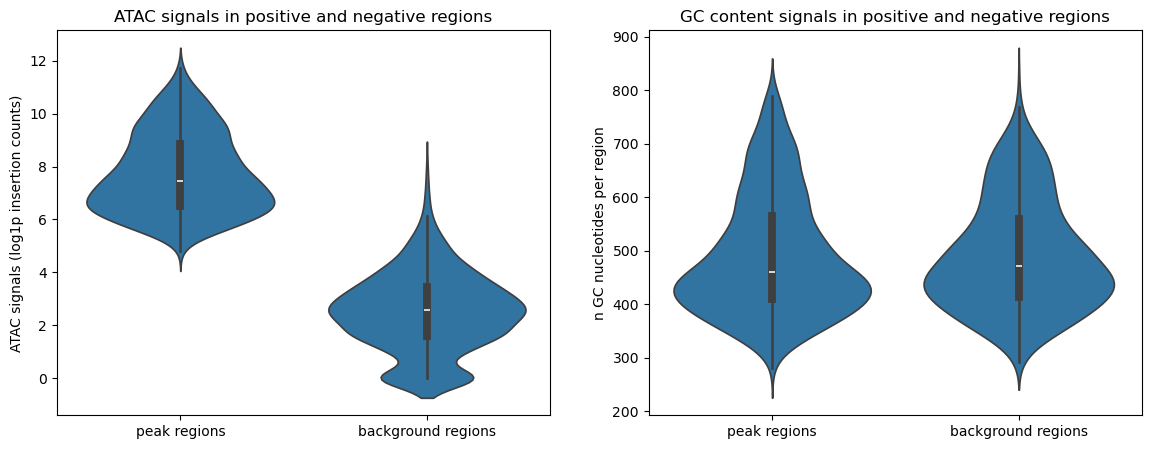

In [31]:
#Signal value distribution

signal_plot_df_peak = pd.DataFrame()
signal_plot_df_peak["signal"] = peak_signal_counts.flatten()
signal_plot_df_peak["region_type"] = "peak regions"

signal_plot_df_bg = pd.DataFrame()
signal_plot_df_bg["signal"] = bg_signal_counts.flatten()
signal_plot_df_bg["region_type"] = "background regions"

signal_plot_df = pd.concat([signal_plot_df_peak, signal_plot_df_bg])

#GC content distribution

peak_seqs_nuc_counts = peak_seqs.sum(axis=2)
peak_seqs_GC_counts = peak_seqs_nuc_counts[:,1:3].sum(axis=-1)

bg_seqs_nuc_counts = bg_seqs.sum(axis=2)
bg_seqs_GC_counts = bg_seqs_nuc_counts[:,1:3].sum(axis=-1)

GC_plot_df_peak = pd.DataFrame()
GC_plot_df_peak["GC content"] = peak_seqs_GC_counts
GC_plot_df_peak["region_type"] = "peak regions"

GC_plot_df_bg = pd.DataFrame()
GC_plot_df_bg["GC content"] = bg_seqs_GC_counts
GC_plot_df_bg["region_type"] = "background regions"

GC_plot_df = pd.concat([GC_plot_df_peak, GC_plot_df_bg])

#Plot signals and GC content

fig, ax = plt.subplots(ncols=2, figsize = (14,5))

sns.violinplot(signal_plot_df,x="region_type",y="signal",ax = ax[0])
ax[0].set_title("ATAC signals in positive and negative regions")
ax[0].set_ylabel("ATAC signals (log1p insertion counts)")
ax[0].set_xlabel("")

sns.violinplot(GC_plot_df,x="region_type",y="GC content",ax = ax[1])
ax[1].set_title("GC content signals in positive and negative regions")
ax[1].set_ylabel("n GC nucleotides per region")
ax[1].set_xlabel("")

<b>We see that background sequences indeed have makedly lower ATAC signal vales while having very similar GC content compared to peak regions.<b>

In [32]:
#Saving peak and control regions to tsv files
os.makedirs(f"{repo_base_dir}/res/ENCODE_cellines/GM12878/curated_regions/",exist_ok=True)

narrow_peaks.to_csv(f"{repo_base_dir}/res/ENCODE_cellines/GM12878/curated_regions/peak_regions_filtered.tsv",sep="\t",index=False)
background_loci_gc_matched.to_csv(f"{repo_base_dir}/res/ENCODE_cellines/GM12878/curated_regions/gc_matched_control_regions_filtered.tsv",sep="\t",index=False)


We have now confirmed that the chosen peak and control regions have the desired properties in terms of ATAC signal strength and nucleotide composition.<br>
<b>Next, we are going to use these regions for training our sequence-to-accessibility models.</b>